# Makemore
It is something that makes more of what it is given an input

In [1]:
from pprint import pprint

In [2]:
words = open("Indian.txt",'r').read().splitlines()
words[:3]

['Aaban', 'Aabharan', 'Aabhas']

In [3]:
print(len(words))
print(min(len(w) for w in words))
print(max(len(w) for w in words))

53982
2
24


In [4]:
b = {}
for w in words:
    w = w.lower()
    chs = ['<S>'] + list(w) + ['<E>']
    for ch1, ch2 in zip(chs,chs[1:]):
        bigram = (ch1,ch2)
        if bigram in b:
            b[bigram] += 1
        elif bigram not in b:
            b[bigram] = 1

In [5]:
pprint(sorted(b.items(), key=lambda x:x[1], reverse=True))


[(('a', 'n'), 25646),
 (('h', 'a'), 18167),
 (('a', '<E>'), 16312),
 (('t', 'h'), 15185),
 (('s', 'h'), 14246),
 (('n', '<E>'), 13513),
 (('a', 'r'), 10752),
 (('r', 'a'), 10543),
 (('i', '<E>'), 8863),
 (('h', 'i'), 8170),
 (('n', 'a'), 7889),
 (('y', 'a'), 7506),
 (('n', 'i'), 6941),
 (('k', 'a'), 6619),
 (('<S>', 'a'), 6476),
 (('v', 'a'), 6045),
 (('m', 'a'), 5546),
 (('a', 's'), 5382),
 (('a', 't'), 5185),
 (('i', 'n'), 5154),
 (('<S>', 's'), 5140),
 (('r', 'i'), 4935),
 (('i', 't'), 4881),
 (('h', '<E>'), 4551),
 (('l', 'a'), 4496),
 (('a', 'a'), 4483),
 (('v', 'i'), 4469),
 (('i', 's'), 4328),
 (('<S>', 'k'), 4233),
 (('e', 'e'), 4232),
 (('s', 'a'), 4203),
 (('<S>', 'v'), 4106),
 (('<S>', 'm'), 3849),
 (('a', 'm'), 3845),
 (('a', 'l'), 3842),
 (('a', 'v'), 3635),
 (('<S>', 'n'), 3551),
 (('e', 's'), 3516),
 (('<S>', 'r'), 3353),
 (('j', 'a'), 3343),
 (('i', 'k'), 3324),
 (('<S>', 'p'), 3289),
 (('d', 'h'), 3034),
 (('n', 't'), 3025),
 (('e', 'n'), 3011),
 (('<S>', 'd'), 2965),


In [6]:
import torch

In [7]:
N = torch.zeros((27,27), dtype = torch.int32)

In [8]:
chars = sorted(list(set((''.join(words)).lower())))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
stoi

{'a': 1,
 'b': 2,
 'c': 3,
 'd': 4,
 'e': 5,
 'f': 6,
 'g': 7,
 'h': 8,
 'i': 9,
 'j': 10,
 'k': 11,
 'l': 12,
 'm': 13,
 'n': 14,
 'o': 15,
 'p': 16,
 'q': 17,
 'r': 18,
 's': 19,
 't': 20,
 'u': 21,
 'v': 22,
 'w': 23,
 'x': 24,
 'y': 25,
 'z': 26,
 '.': 0}

In [9]:
for w in words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs,chs[1:]):
        ch1 = ch1.lower()
        ch2 = ch2.lower()
        row = stoi[ch1]
        col = stoi[ch2] 
        bigram = (row,col)
        N[bigram] += 1

In [10]:
itos = {i:s for s,i in stoi.items()}
itos

{1: 'a',
 2: 'b',
 3: 'c',
 4: 'd',
 5: 'e',
 6: 'f',
 7: 'g',
 8: 'h',
 9: 'i',
 10: 'j',
 11: 'k',
 12: 'l',
 13: 'm',
 14: 'n',
 15: 'o',
 16: 'p',
 17: 'q',
 18: 'r',
 19: 's',
 20: 't',
 21: 'u',
 22: 'v',
 23: 'w',
 24: 'x',
 25: 'y',
 26: 'z',
 0: '.'}

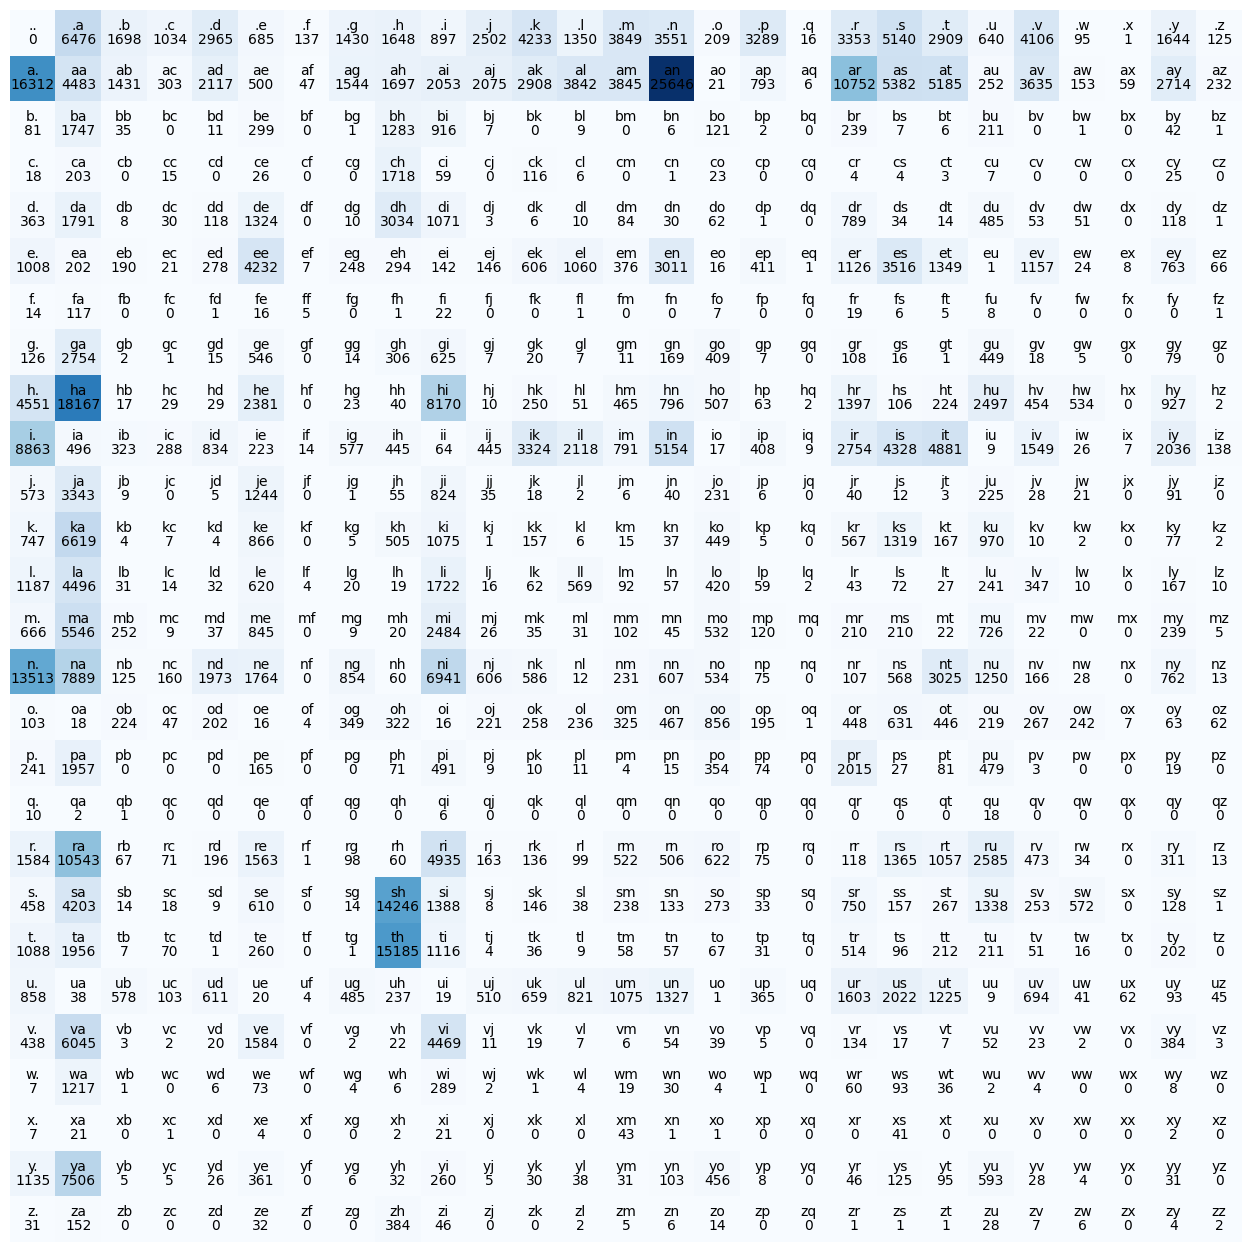

In [11]:
import matplotlib.pyplot as plt
%matplotlib inline
# plt.imshow(N)

plt.figure(figsize = (16,16))
plt.imshow(N, cmap = 'Blues')
for i in range(27):
    for j in range(27):
        chstr = itos[i] + itos[j] 
        plt.text(j,i, chstr , ha="center", va="bottom", color= 'black')
        plt.text(j,i, N[i,j].item() , ha="center", va="top", color= 'black')
plt.axis('off');

In [12]:
N[0]

tensor([   0, 6476, 1698, 1034, 2965,  685,  137, 1430, 1648,  897, 2502, 4233,
        1350, 3849, 3551,  209, 3289,   16, 3353, 5140, 2909,  640, 4106,   95,
           1, 1644,  125], dtype=torch.int32)

In [13]:
P = (N).float()
sm = P.sum(1,keepdim=True)
P = P/sm

In [14]:
g = torch.Generator().manual_seed(2147483647)

In [15]:
for _ in range(10):
    ix = 0
    name = ""
    while True:
        p = P[ix]
        ix = torch.multinomial(p,1,replacement=True, generator=g).item()
        if ix == 0:
            break
        ch = itos[ix]
        name += ch
    print(name)

deeba
pogakurari
jitaharvinimithain
lanak
kan
a
sa
ripubatharugothi
mi
jeelavuja


# Evaluation of the bi-gram model

Training set : Names which are broken down into pairs of consecutive characters (x,y). 

Parameters : Conditional probability of 'j' being followed by 'i'. Where i,j belongs to {alphabet + '.'}
Therefore: P

input : one hot encoding of character : a = (1,0,0,...,0) , b = (0,1,0,0,...,0)

model (output): p_(j|i) = P @ x

Prediction  : It predicts the character by sampling a character based on the output distribution

Using MLE, we can define the loss of this model to be NLL

In [40]:
import math
print('Negative Log Likelihoods:')
w_prob = 0
n = 0
for w in words:
    w = w.lower()
    chs = ['.'] + list(w) + ['.']
    for ch1,ch2 in zip(chs,chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        prob = P[ix1,ix2]
        n+=1
        w_prob -= math.log(prob)
        # print(f'{ch1}{ch2}: {prob*100:.3f} %')
    # print(f'{w}: {w_prob*100:.8f}')
print(w_prob/n)


Negative Log Likelihoods:
2.175545349504192


In [41]:
xs = [stoi[ch.lower()] for w in words for ch in '.'+ w]
xs = torch.tensor(xs)
xs.shape

torch.Size([488074])

In [42]:
ys = [stoi[ch.lower()] for w in words for ch in w+'.']
ys = torch.tensor(ys)
ys.shape

torch.Size([488074])

In [43]:
# one hot encoding of the inputs
import torch.nn.functional as F 
xenc = F.one_hot(xs,num_classes=27).float()

In [44]:
import torch
g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27,27),generator=g,requires_grad=True)
learning_rate = 10

for _ in range(500):
    #forward pass
    logits = xenc@W
    counts = logits.exp()
    probs = (counts)/counts.sum(dim = 1, keepdim=True)
    loss = -probs[torch.arange(len(xs)),ys].log().mean()
    print(loss)

    #backward pass
    W.grad = None
    loss.backward()
    W.data += - learning_rate * W.grad

tensor(3.7613, grad_fn=<NegBackward0>)
tensor(3.6245, grad_fn=<NegBackward0>)
tensor(3.5010, grad_fn=<NegBackward0>)
tensor(3.3907, grad_fn=<NegBackward0>)
tensor(3.2935, grad_fn=<NegBackward0>)
tensor(3.2085, grad_fn=<NegBackward0>)
tensor(3.1339, grad_fn=<NegBackward0>)
tensor(3.0681, grad_fn=<NegBackward0>)
tensor(3.0097, grad_fn=<NegBackward0>)
tensor(2.9578, grad_fn=<NegBackward0>)
tensor(2.9115, grad_fn=<NegBackward0>)
tensor(2.8701, grad_fn=<NegBackward0>)
tensor(2.8331, grad_fn=<NegBackward0>)
tensor(2.7999, grad_fn=<NegBackward0>)
tensor(2.7700, grad_fn=<NegBackward0>)
tensor(2.7431, grad_fn=<NegBackward0>)
tensor(2.7187, grad_fn=<NegBackward0>)
tensor(2.6965, grad_fn=<NegBackward0>)
tensor(2.6762, grad_fn=<NegBackward0>)
tensor(2.6575, grad_fn=<NegBackward0>)
tensor(2.6403, grad_fn=<NegBackward0>)
tensor(2.6244, grad_fn=<NegBackward0>)
tensor(2.6096, grad_fn=<NegBackward0>)
tensor(2.5958, grad_fn=<NegBackward0>)
tensor(2.5829, grad_fn=<NegBackward0>)
tensor(2.5708, grad_fn=<N

In [45]:
g = torch.Generator().manual_seed(2147483647)
#Sampling from the NN
for _ in range(10):
    new_word = ""
    ix = 0
    while True:
        xenc = F.one_hot(torch.tensor([ix]),num_classes=27).float()
        logits = xenc @ W 
        counts = logits.exp()
        probs = counts/counts.sum(1,keepdim=True)

        ix = torch.multinomial(probs, num_samples=1, replacement=True,generator=g).item()
        ch = itos[ix]
        new_word += ch
        if ix == 0:
            break
    print(new_word)

deeba.
pogakurari.
jitaharvinimithain.
lanak.
kan.
a.
sa.
ripubjansrugothi.
mi.
jeelavuja.
